# A rock factor that uses nothing from the target site, and how much of the classical score was borrowed

**Level 4: Beyond the state of the art** · Needs: 02-classical-prediction/02-the-rock-factor, 02-classical-prediction/03-the-published-hold-out-tables · Reading time: about 30 minutes

## Objectives

The classical arm of the previous notebooks reads a rock factor that was recovered from the published predictions for the very site it is scored on. Held out by site, that is knowledge of the held-out site, which a learned arm is never given. This notebook measures how much of the classical score that knowledge buys, by replacing the site constant with a factor predicted from the rock's Young modulus using the other sites only (claim BS-4).

By the end you will have:

- fitted the log-linear relation between the recovered factors and the site moduli and compared it with the committed fit;
- scored the site-constant arm and the transfer arm under leave-one-site-out and with a site-resampled interval, and matched the committed benchmark;
- read, site by site, the factor the transfer arm predicts against the factor recovered from the paper.

## Setup

Install the packages with the exact pins of `notebooks/requirements.txt`. The engine is `blastfrag`, published on PyPI; the other packages are its numerical base and the plotting library.

```bash
pip install blastfrag==0.4.0 numpy==2.5.3 matplotlib==3.11.2
```

This cell imports nothing from the notebook yet: it reads the installed versions from the package metadata and prints them, so the output records exactly which engine produced every number below.

In [1]:
# Print the installed version of every package this notebook uses
from importlib.metadata import version

for name in ("blastfrag", "numpy", "matplotlib",):
    print(f"{name}=={version(name)}")

blastfrag==0.4.0
numpy==2.5.3
matplotlib==3.11.2


## Data

| Source | Owner and URL | Licence class | File the notebook reads |
|---|---|---|---|
| The 97 blasts, their moduli and the recovered per-site factors | Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957; Kulatilake, Hudaverdi and Wu 2012, https://doi.org/10.1007/s10706-012-9496-3 | numeric facts reused with citation; the articles never ship | the corpus and `bf.SITE_ROCK_FACTOR` inside the `blastfrag` wheel |
| The committed fit and the committed leave-one-site-out scores | this repository (MIT), written by the offline bake | the product's own licence | `data/derived/benchmark.json`, fields `diagnostics.transfer_fit` and `protocols` |

## Method

The transfer arm fits one straight line in logarithms through the training sites,

```
ln A = a + b * ln E
```

with one point per site (the site's recovered factor against its mean modulus), so a 22-blast quarry and a six-blast mine weigh the same. The factor of a blast is then `exp(a + b ln E)` from its own modulus, which an engineer has before the first blast at a new mine. The relation is a calibration of the engine, not a published equation. Under leave-one-site-out the line is refitted without the held-out site on every fold.

The interval is a bootstrap that resamples **sites**, not blasts, because rows of one campaign are not independent draws (Roberts et al. 2017, https://doi.org/10.1111/ecog.02881).

## State of the art

- The two source papers (Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957; Kulatilake, Hudaverdi and Wu 2012, https://doi.org/10.1007/s10706-012-9496-3) state that the rock factor was estimated for each blast and print no value. The factors recovered from their predictions behave as a per-site constant (notebook 02 of this topic: a spread of a few percent inside a site).
- Any evaluation of the classical equation that uses those factors on the same site therefore gives the equation a number tuned to the site, and the SDD's research basis notes that the published learned-predictor studies do not hold out a whole mine. A held-out-site score of such an arm cannot separate the equation's skill from the factor's origin.
- Resampling the right unit matters: cross-validation that ignores dependence in the data can seriously underestimate prediction error (Roberts et al. 2017, https://doi.org/10.1111/ecog.02881).

## Beyond the state of the art

### Step 1: fit the relation on all sites

The cell fits `KuznetsovTransfer` on the whole corpus, prints its intercept and slope beside the committed fit, and computes the correlation between the site moduli and the recovered factors, in logarithms.

fitted here:  intercept = 0.384106  slope = 0.502909
committed:      intercept = 0.384106  slope = 0.502909
same sites: True
correlation of ln A with ln E over the sites = 0.891


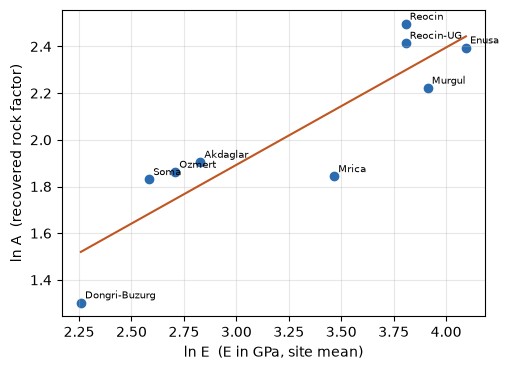

In [2]:
# Imports, then the fit over all nine sites with a recovered factor, against the committed fit
import json
from pathlib import Path

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np

DERIVED = Path("../../../data/derived")
train = bf.load_training_corpus()
benchmark = json.loads((DERIVED / "benchmark.json").read_text(encoding="utf-8"))
committed = benchmark["diagnostics"]["transfer_fit"]
transfer = bf.KuznetsovTransfer().fit(train)
print(f"fitted here:  intercept = {transfer.intercept:.6f}  slope = {transfer.slope:.6f}")
print(f"committed:      intercept = {committed['intercept']:.6f}  slope = {committed['slope']:.6f}")
print("same sites:", list(transfer.fit_sites) == committed["fit_sites"])

sites = list(transfer.fit_sites)
log_e = np.log([np.mean([b.E_GPa for b in train if b.site == s]) for s in sites])
log_a = np.log([bf.SITE_ROCK_FACTOR[s] for s in sites])
print(f"correlation of ln A with ln E over the sites = {np.corrcoef(log_e, log_a)[0, 1]:.3f}")

fig, ax = plt.subplots(figsize=(5.2, 3.8))
ax.scatter(log_e, log_a, color="#2b6cb0")
for s, x, y in zip(sites, log_e, log_a):
    ax.annotate(s, (x, y), fontsize=7, xytext=(3, 3), textcoords="offset points")
grid = np.linspace(log_e.min(), log_e.max(), 20)
ax.plot(grid, transfer.intercept + transfer.slope * grid, color="#c05621")
ax.set_xlabel("ln E  (E in GPa, site mean)")
ax.set_ylabel("ln A  (recovered rock factor)")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

### Step 2: leave one site out, twice

For each of the ten sites the cell trains on the other nine, predicts the held-out site with both the site-constant arm and the transfer arm, and records the factor the transfer arm used. Miami has no geometry, so both arms abstain there. The transfer arm's line is refitted without the held-out site on every fold.

In [3]:
# Leave-one-site-out for the two classical arms, keeping the factor the transfer arm predicted for each site
tested, predictions, factors = [], {"kuznetsov": [], "kuznetsov-transfer": [], "null": []}, {}
for split in bf.leave_one_site_out(train):
    site = split.detail["held_out_site"]
    site_constant = bf.Kuznetsov().fit(split.train)
    transferred = bf.KuznetsovTransfer().fit(split.train)
    predictions["kuznetsov"] += site_constant.predict(split.test)
    predictions["kuznetsov-transfer"] += transferred.predict(split.test)
    predictions["null"] += bf.NullModel().fit(split.train).predict(split.test)
    tested += list(split.test)
    factors[site] = transferred.rock_factor_for(float(np.mean([b.E_GPa for b in split.test])))
print(f"{'held-out site':<16}{'recovered A':>16}{'predicted A (other sites only)':>38}")
for site, predicted in factors.items():
    recovered = bf.SITE_ROCK_FACTOR.get(site)
    print(f"{site:<16}" + (f"{recovered:>16.2f}" if recovered else f"{'-':>16}") + f"{predicted:>38.2f}")

held-out site        recovered A        predicted A (other sites only)
Akdaglar                    6.72                                  5.97
Dongri-Buzurg               3.68                                  5.25
Enusa                      10.97                                 11.74
Miami                          -                                  4.67
Mrica                       6.32                                  8.72
Murgul                      9.23                                 10.89
Ozmert                      6.44                                  5.57
Reocin                     12.14                                  9.51
Reocin-UG                  11.19                                  9.69
Soma                        6.24                                  5.14


### Step 3: score both arms, with a site-resampled interval, against the committed benchmark

Both classical arms are scored on the 91 blasts with a resolvable geometry. The interval resamples sites 2000 times with the benchmark's seed, so it can be compared with the committed one exactly. The null model, which predicts the mean of the training sites, is scored on the same rows for reference.

In [4]:
# Score each arm on the rows it answers, with a site-resampled 95 percent interval, and compare with the committed values
loso = benchmark["protocols"]["leave-one-site-out"]["arms"]
print(f"{'arm':<22}{'n':>4}{'r2 identity':>14}{'interval 95 %':>26}  equals committed")
for name, predicted in predictions.items():
    answered = [(b, p) for b, p in zip(tested, predicted) if p.x50_m is not None and bf.has_absolute_geometry(b)]
    rows, preds = [a[0] for a in answered], [a[1] for a in answered]
    point, low, high = bf.bootstrap_interval(rows, preds, "r2_identity", n_boot=2000, unit="site", seed=0)
    want = loso[name]["supports"]["geometry"]
    same = abs(point - want["score"]["r2_identity"]) < 1e-9 and abs(low - want["interval_95"][0]) < 1e-9 and abs(high - want["interval_95"][1]) < 1e-9
    print(f"{name:<22}{len(rows):>4}{point:>14.4f}{f'{low:.3f} to {high:.3f}':>26}  {same}")
    if name == "null":
        print("(the null predicts the mean of the other sites, refitted on every fold)")

arm                      n   r2 identity             interval 95 %  equals committed
kuznetsov               91        0.3112           -0.966 to 0.686  True
kuznetsov-transfer      91        0.2982           -1.097 to 0.708  True
null                    91       -0.2320          -1.330 to -0.158  True
(the null predicts the mean of the other sites, refitted on every fold)


## Results

**The relation is real but loose.** The recovered factors and the site moduli correlate strongly in logarithms, so a rock factor can be predicted from the modulus to within about 45 percent in every fold. Site by site the predicted factor lands close for some sites and far for others (the fold table), and the line is refitted without the held-out site each time.

**Replacing the site constant barely moves the score.** Under leave-one-site-out the transfer arm's variance explained about the identity line is within a few hundredths of the site-constant arm's, and both intervals, which resample sites, span zero by a wide margin. The notebook's numbers equal the committed benchmark to the last digit. So the classical score was not mainly borrowed from the held-out site: it survives having the site's own factor replaced by one predicted from the modulus alone.

**What this does and does not claim.** It supports one statement: the classical arm's cross-site score does not depend on the site constant. It does not say the classical equation has skill at a new mine, because the interval spans zero, and it does not make the factors independent of the published predictions: the line is still fitted to factors recovered from them, for the other sites. The arm is a calibration of this engine, not a published relation.

**Why it matters.** Without this arm, a reader comparing the classical arm with the learned ones under leave-one-site-out could not tell whether the classical arm's score was earned or lent. With it, the answer is on the page, in both the point score and the interval.

## Summary

- The transfer arm predicts the rock factor from the Young modulus by a log-linear line over the other sites, so it uses nothing from the site it is scored on (claim BS-4).
- Under leave-one-site-out it scores within a few hundredths of the site-constant arm, and both intervals span zero: the classical score was not borrowed, and it is not skill either.
- The notebook reproduces the committed benchmark to the last digit.
- Next: topic 03 turns a mean size into a whole size distribution.

## References

- Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 (the corpus and the factor that was estimated for each blast)
- Kulatilake, Hudaverdi and Wu 2012, https://doi.org/10.1007/s10706-012-9496-3 (the 2012 hold-out whose column the factors are recovered from)
- Roberts et al. 2017, https://doi.org/10.1111/ecog.02881 (resampling the right unit under dependence)
- `blastfrag` 0.4.0, the engine, on PyPI: https://pypi.org/project/blastfrag/